# AI301 Assignment #2

**Goal of this notebook:** a pretrained EfficientNet baseline with per-class thresholds, logged training curves and gradient-flow plots, plus a few focused EDA checks (class imbalance, label co-occurrence, image quality, train-vs-test shift, near-duplicates).

## 1. Setup & config

In [1]:
%load_ext autoreload
%autoreload 2

import os, random, time, warnings

# Pick the GPU before torch starts CUDA. The local machine is shared: GPUs 0 and 1 were idle (check with nvidia-smi).
# Kaggle gives its own GPU(s), so leave the choice to Kaggle there.
if not os.path.exists("/kaggle/input"):
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
from multiprocessing import Pool
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dctn
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold, MultilabelStratifiedShuffleSplit
from sklearn.metrics import f1_score, average_precision_score, precision_recall_curve
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
import timm

from cnn_lab.viz import label_code, label_names, show_grid

warnings.filterwarnings("ignore")

/home/nvidia/Documents/cnn-lab/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
def seed_everything(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
seed_everything()

In [3]:
CFG = dict(
    model_name="efficientnet_b4.ra2_in1k",   # timm EfficientNet-B4, ImageNet-1k weights
    img_size=384,            # B4 was trained at 320 px and evaluated at 384 (timm pretrained_cfg); images are 450x375
    batch_size=64,
    epochs=20,               # max epochs; early stopping usually ends training sooner
    patience=3,              # stop after this many epochs without a val loss improvement
    min_delta=0.0005,        # val loss must drop by more than this to count as an improvement (and a new best checkpoint)
    lr=1e-3,                 # peak LR of the new classifier head
    backbone_lr_mult=0.1,    # the pretrained body learns 10x slower than the head
    weight_decay=1e-2,
    drop_rate=0.3,           # dropout before the classifier
    drop_path_rate=0.2,      # stochastic depth: randomly skips MBConv blocks during training
    n_folds=1,               # 1 = one stratified hold-out (val_frac of train); >1 = multilabel stratified K-fold
    val_frac=0.2,            # val share of train when n_folds=1
    num_workers=min(16, os.cpu_count()),   # DataLoader workers that run the augmentations (Kaggle has 4 CPUs)
    grad_log_every=25,       # record per-stage gradient norms every N steps (for the gradient-flow plot)
    debug=False,             # True = smoke test: 640 train / 256 val images per trained fold, 1 epoch
)

if CFG["debug"]:
    CFG["epochs"] = 1

RUN_NAME = CFG["model_name"].split(".")[0]   # used in output file names, e.g. efficientnet_b4_history.csv
FOLDS = list(range(CFG["n_folds"]))          # one model is trained per fold; fold k = the val images of model k

In [4]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, "| timm", timm.__version__)

if DEVICE == "cpu":
    print("\n" + "!" * 70 + "\n!! NO GPU DETECTED -> training will take hours. Enable it in\n"
          "!! Settings (right sidebar) -> Accelerator -> GPU T4 x2 / P100, then restart.\n" + "!" * 70)
else:
    print("GPU:", torch.cuda.get_device_name(0))

device: cuda | timm 1.0.30
GPU: NVIDIA H100 NVL


## 2. Locate the data

In [5]:
# Kaggle mounts the competition data under /kaggle/input; locally it sits in data/ and images/
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    train_csv = next(Path("/kaggle/input").rglob("train.csv"), None)
    assert train_csv, "train.csv not found under /kaggle/input, attach the competition data"
    DATA_DIR = train_csv.parent
    IMG_DIR = DATA_DIR
    CACHE_DIR = Path("/kaggle/temp")
    OUT_DIR = Path("/kaggle/working")
else:
    # The kernel may start in notebooks/ or in the repo root
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_DIR = ROOT / "data"
    IMG_DIR = ROOT / "images"
    CACHE_DIR = ROOT / "cache"
    OUT_DIR = ROOT / "output"

CACHE_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
print("DATA_DIR:", DATA_DIR, "| IMG_DIR:", IMG_DIR)

DATA_DIR: /home/nvidia/Documents/cnn-lab/data | IMG_DIR: /home/nvidia/Documents/cnn-lab/images


In [6]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

LABELS = sample_sub.columns.drop("image_id").tolist()
print("labels:", LABELS)
print("train", train.shape, "| test", test.shape, "| sample_submission", sample_sub.shape)

labels: ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']
train (12260, 6) | test (18673, 1) | sample_submission (18673, 6)


In [7]:
# Each image lives at {IMG_DIR}/{split}/{image_id}.jpg
train["path"] = [str(IMG_DIR / "train" / f"{i}.jpg") for i in train.image_id]
test["path"] = [str(IMG_DIR / "test" / f"{i}.jpg") for i in test.image_id]

missing = [p for p in [*train.path, *test.path] if not os.path.exists(p)]
assert not missing, f"{len(missing)} images missing, e.g. {missing[0]}"

## 3. Train / test / submission format

In [8]:
print("--- train.csv (example rows) ---")
display(train.drop(columns="path").head(3))

print("--- test.csv (example rows) ---")
display(test.drop(columns="path").head(3))

print("--- sample_submission.csv (example rows) ---")
display(sample_sub.head(3))

print("Duplicate image_ids in train:", train.image_id.duplicated().sum())

--- train.csv (example rows) ---


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0


--- test.csv (example rows) ---


,image_id
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c
2,ac89f642faef21c92d622d882943e9065600354a


--- sample_submission.csv (example rows) ---


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24,1,1,1,1,1
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c,1,1,1,1,1
2,ac89f642faef21c92d622d882943e9065600354a,1,1,1,1,1


Duplicate image_ids in train: 0


## 4. EDA — focused on what affects modelling

In [9]:
# Class prevalence: how many positives each label has
counts = train[LABELS].sum().sort_values(ascending=False)

prevalence = pd.DataFrame({
    "positives": counts,
    "prevalence_%": (counts / len(train) * 100).round(2),
    "neg:pos ratio": ((len(train) - counts) / counts).round(1),
})
display(prevalence)

,positives,prevalence_%,neg:pos ratio
Cat,5077,41.41,1.4
Dog,5025,40.99,1.4
Moris,56,0.46,217.9
Motya,42,0.34,290.9
Biatrix,41,0.33,298.0


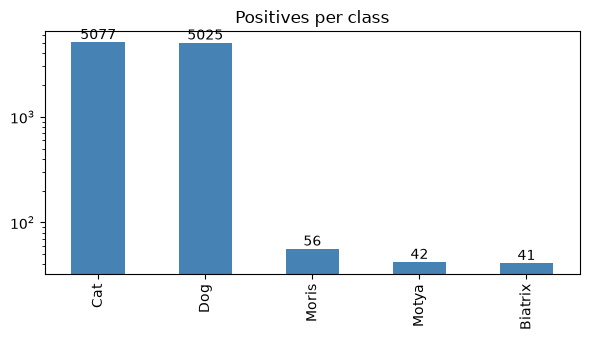

In [10]:
# Positives per class (log scale, so the rare classes stay visible)
ax = counts.plot.bar(figsize=(6, 3.5), color="steelblue", logy=True, title="Positives per class")
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

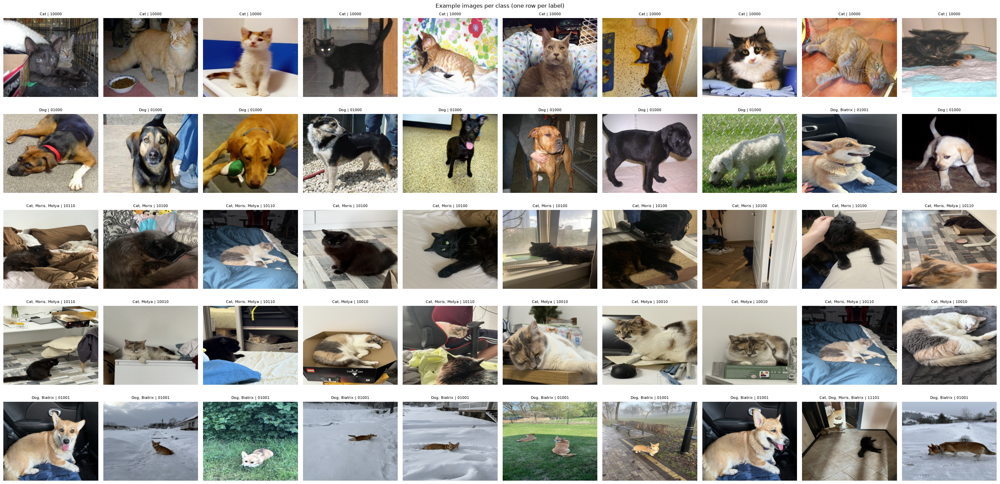

In [11]:
samples = [train[train[label] == 1].sample(10, random_state=SEED) for label in LABELS]
show_grid(samples, LABELS, suptitle="Example images per class (one row per label)")

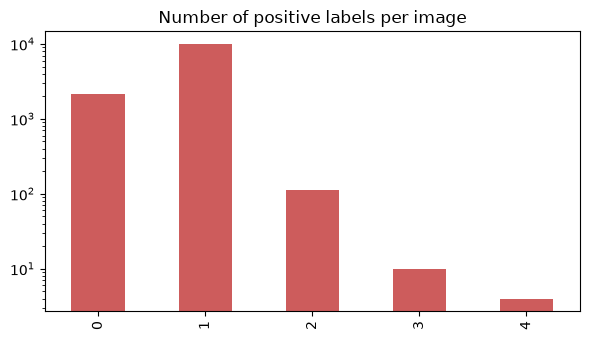

In [12]:
# How many positive labels each image has (0 = background / other)
n_labels = train[LABELS].sum(axis=1)

n_labels.value_counts().sort_index().plot.bar(
    figsize=(6, 3.5), color="indianred", logy=True, title="Number of positive labels per image"
)
plt.tight_layout()
plt.show()

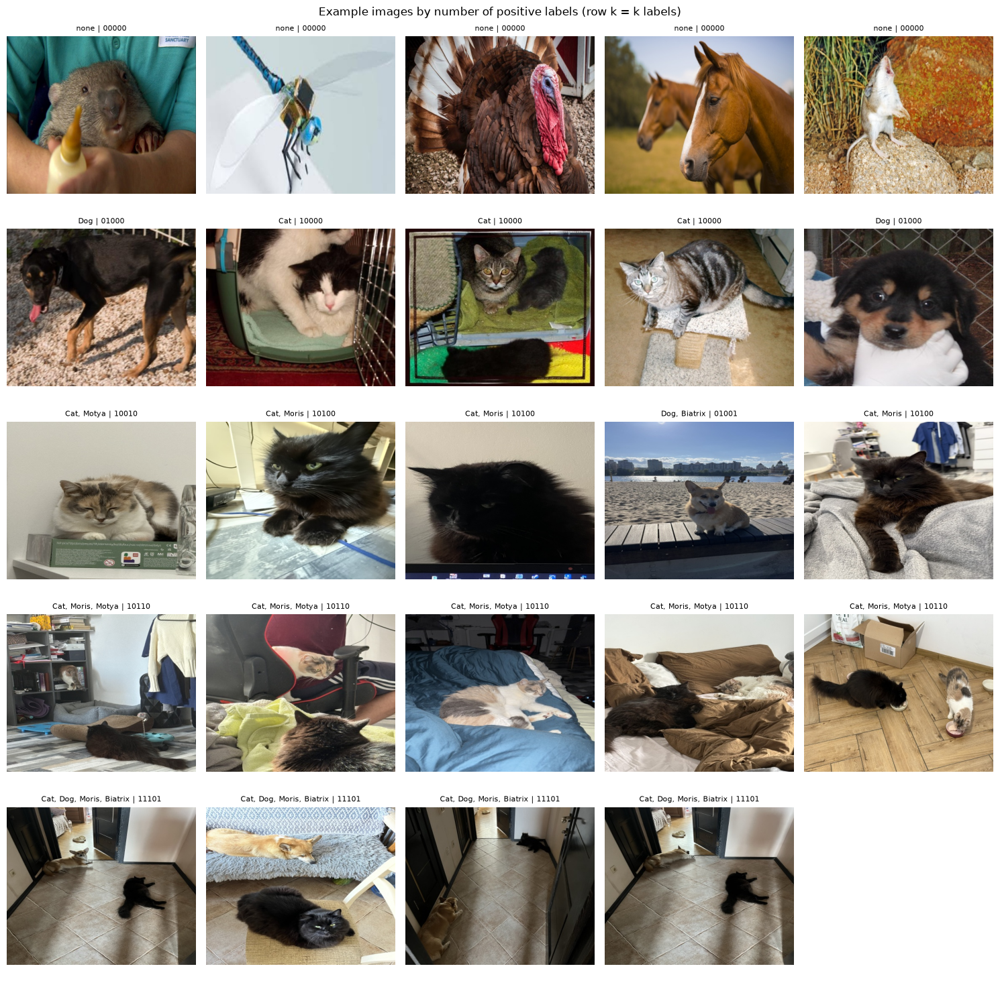

In [13]:
samples = [group.sample(min(5, len(group)), random_state=SEED) for _, group in train.groupby(n_labels)]
show_grid(samples, LABELS, suptitle="Example images by number of positive labels (row k = k labels)")

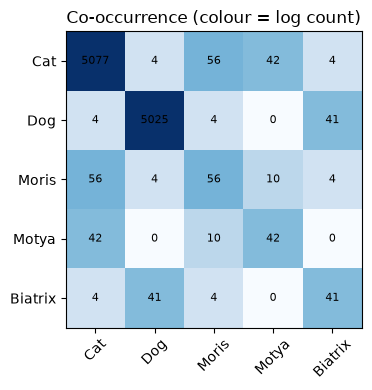

,count,pattern
10000,4989,10000
01000,4984,01000
00000,2162,00000
10100,42,10100
01001,37,01001
10010,32,10010
10110,10,10110
11101,4,11101


Pattern order: ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']


In [14]:
co = train[LABELS].T.dot(train[LABELS])
plt.figure(figsize=(5, 4)); plt.imshow(np.log1p(co.values), cmap="Blues")
plt.xticks(range(5), LABELS, rotation=45); plt.yticks(range(5), LABELS)
for i in range(5):
    for j in range(5): plt.text(j, i, int(co.values[i, j]), ha="center", va="center", fontsize=8)
plt.title("Co-occurrence (colour = log count)"); plt.tight_layout(); plt.show()

combo = train[LABELS].astype(str).agg("".join, axis=1).value_counts()
display(combo.rename("count").to_frame().assign(pattern=lambda d: d.index).head(12))
print("Pattern order:", LABELS)

### Image quality: train vs test
Every image is checked (not a sample). All stats are computed on a 256×256 copy so they are comparable across images.
- **brightness**: mean grey level (0 = black, 1 = white)
- **contrast**: std of grey levels (≈0 = flat / blank image)
- **saturation**: mean (max − min) over RGB channels (≈0 = grayscale)
- **sharpness**: log10 variance of the Laplacian (low = blurry)

In [15]:
LUMA = np.array([0.299, 0.587, 0.114], dtype=np.float32)   # RGB -> grey weights

def img_stats(path):
    with Image.open(path) as im:
        w, h = im.size
        im.draft("RGB", (256, 256))   # let the JPEG decoder skip full resolution (much faster)
        rgb = np.asarray(im.convert("RGB").resize((256, 256)), dtype=np.float32) / 255

    gray = rgb @ LUMA
    laplacian = gray[:-2, 1:-1] + gray[2:, 1:-1] + gray[1:-1, :-2] + gray[1:-1, 2:] - 4 * gray[1:-1, 1:-1]
    return dict(
        w=w,
        h=h,
        brightness=gray.mean(),
        contrast=gray.std(),
        saturation=(rgb.max(axis=2) - rgb.min(axis=2)).mean(),
        sharpness=np.log10(laplacian.var() + 1e-8),
    )

In [16]:
with Pool() as pool:
    tr_s = pd.DataFrame(pool.map(img_stats, train.path, chunksize=64))
    te_s = pd.DataFrame(pool.map(img_stats, test.path, chunksize=64))

print("Image sizes (w, h) in train:", tr_s.value_counts(["w", "h"]).to_dict())
print("Image sizes (w, h) in test: ", te_s.value_counts(["w", "h"]).to_dict())
display(pd.concat({"train": tr_s.describe().T, "test": te_s.describe().T}, axis=1).round(3))

Image sizes (w, h) in train: {(450, 375): 12260}
Image sizes (w, h) in test:  {(450, 375): 18673}


train                                                      \
              count     mean    std      min      25%      50%      75%   
w           12260.0  450.000  0.000  450.000  450.000  450.000  450.000   
h           12260.0  375.000  0.000  375.000  375.000  375.000  375.000   
brightness  12260.0    0.467  0.121    0.029    0.390    0.462    0.534   
contrast    12260.0    0.216  0.054    0.040    0.179    0.214    0.252   
saturation  12260.0    0.125  0.081    0.000    0.070    0.106    0.159   
sharpness   12260.0   -2.224  0.402   -3.903   -2.494   -2.228   -1.952   

                        test                                             \
                max    count     mean    std      min      25%      50%   
w           450.000  18673.0  450.000  0.000  450.000  450.000  450.000   
h           375.000  18673.0  375.000  0.000  375.000  375.000  375.000   
brightness    0.985  18673.0    0.467  0.120    0.018    0.391    0.464   
contrast      0.477  18673.0    0.217  0.054    0.000    0.179    0.215   
saturation    0.885  18673.0    0.124  0.081    0.000    0.068    0.105   
sharpness    -0.850  18673.0   -2.230  0.408   -8.000   -2.500   -2.234   

                              
                75%      max  
w           450.000  450.000  
h           375.000  375.000  
brightness    0.534    1.000  
contrast      0.252    0.430  
saturation    0.158    0.830  
sharpness    -1.959   -0.779

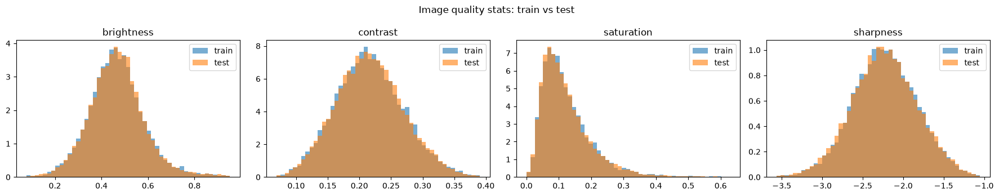

In [17]:
QUALITY_STATS = ["brightness", "contrast", "saturation", "sharpness"]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, QUALITY_STATS):
    # Clip the x-range to the 0.1-99.9 percentiles so a few blank images don't squash the plot
    lo, hi = np.percentile(pd.concat([tr_s[col], te_s[col]]), [0.1, 99.9])
    bins = np.linspace(lo, hi, 50)
    ax.hist(tr_s[col], bins=bins, alpha=0.6, density=True, label="train")
    ax.hist(te_s[col], bins=bins, alpha=0.6, density=True, label="test")
    ax.set_title(col)
    ax.legend()
fig.suptitle("Image quality stats: train vs test")
plt.tight_layout()
plt.show()

In [18]:
# name: (stat, direction, threshold). Thresholds pick roughly the most extreme ~1% of images
QUALITY_CHECKS = {
    "grayscale": ("saturation", "<", 0.02),
    "very dark": ("brightness", "<", 0.15),
    "very bright": ("brightness", ">", 0.85),
    "low contrast": ("contrast", "<", 0.08),
    "blurry": ("sharpness", "<", -3.5),
}

def is_flagged(stats, stat, direction, threshold):
    return stats[stat] < threshold if direction == "<" else stats[stat] > threshold

summary = pd.DataFrame({
    name: {
        "train": is_flagged(tr_s, *check).sum(),
        "test": is_flagged(te_s, *check).sum(),
        "train_%": is_flagged(tr_s, *check).mean() * 100,
        "test_%": is_flagged(te_s, *check).mean() * 100,
    }
    for name, check in QUALITY_CHECKS.items()
}).T
display(summary.round(2))

,train,test,train_%,test_%
grayscale,124.0,209.0,1.01,1.12
very dark,41.0,94.0,0.33,0.50
very bright,97.0,154.0,0.79,0.82
low contrast,23.0,46.0,0.19,0.25
blurry,23.0,29.0,0.19,0.16


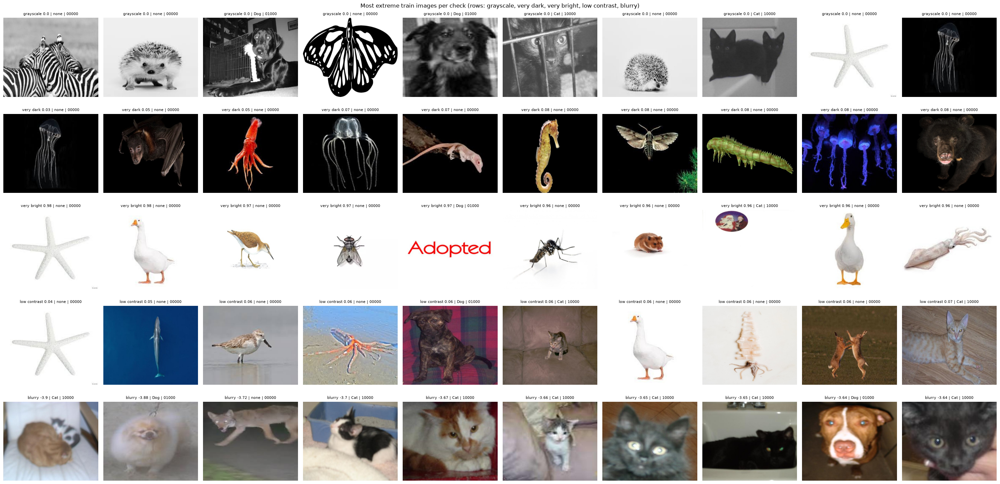

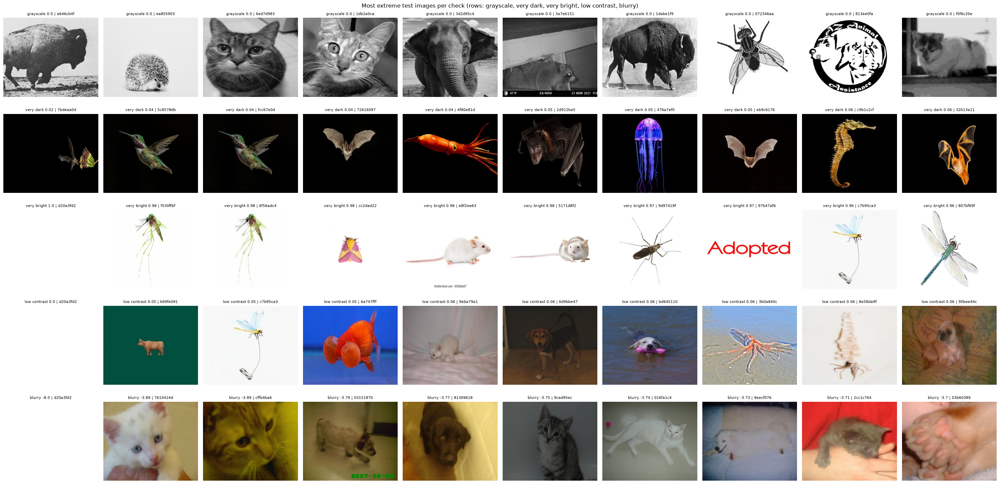

In [19]:
def most_extreme(df, stats, n=10):
    """One DataFrame per quality check: the n most extreme images, with a `reason` column for the title."""
    df = df.join(stats)
    rows = []
    for name, (stat, direction, _) in QUALITY_CHECKS.items():
        worst = df.sort_values(stat, ascending=(direction == "<")).head(n)
        rows.append(worst.assign(reason=name + " " + worst[stat].round(2).astype(str)))
    return rows

checks = ", ".join(QUALITY_CHECKS)
show_grid(most_extreme(train, tr_s), title=lambda r: f"{r.reason} | {label_names(r, LABELS)} | {label_code(r, LABELS)}",
          suptitle=f"Most extreme train images per check (rows: {checks})")
# Test has no labels, so show the start of the image_id instead
show_grid(most_extreme(test, te_s), title=lambda r: f"{r.reason} | {r.image_id[:8]}",
          suptitle=f"Most extreme test images per check (rows: {checks})")

### Near-duplicates (train–train, train–test, test–test)
Each image gets a 64-bit **perceptual hash** (pHash): the signs of the lowest DCT frequencies of a 32×32 grey thumbnail.
Re-encoded, slightly resized or recoloured copies of a photo get (almost) the same hash. We call two images duplicates
when their hashes differ in at most `MAX_HASH_DIST` bits. Larger distances start matching *different* objects on a plain
background, so the threshold is kept tight.

Why it matters: duplicates split across train/val inflate CV, and train–test duplicates tell how much the leaderboard rewards memorisation.

In [20]:
def phash(path):
    """64-bit perceptual hash: is each low-frequency DCT coefficient above the median?"""
    with Image.open(path) as im:
        gray = np.asarray(im.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
    low = dctn(gray, norm="ortho")[:8, :8].ravel()[1:]   # 63 lowest frequencies, without the mean (DC) term
    bits = np.append(low > np.median(low), False)         # pad to 64 bits
    return np.packbits(bits).view(">u8")[0]

all_imgs = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)
with Pool() as pool:
    hashes = np.array(pool.map(phash, all_imgs.path, chunksize=64), dtype=np.uint64)

In [21]:
MAX_HASH_DIST = 2

# Compare every image with every other one, in chunks to keep memory small
pair_i, pair_j = [], []
for start in range(0, len(hashes), 1000):
    dist = np.bitwise_count(hashes[start:start + 1000, None] ^ hashes[None, :])   # Hamming distance
    i, j = np.nonzero(dist <= MAX_HASH_DIST)
    i += start
    keep = i < j                                                                     # each pair once, no self-pairs
    pair_i.append(i[keep])
    pair_j.append(j[keep])
pairs = pd.DataFrame({"i": np.concatenate(pair_i), "j": np.concatenate(pair_j)})
pairs["kind"] = all_imgs.split[pairs.i].values + "-" + all_imgs.split[pairs.j].values

# Duplicate groups = connected components of the "is duplicate" graph (singletons get their own group)
n = len(all_imgs)
graph = coo_matrix((np.ones(len(pairs)), (pairs.i, pairs.j)), shape=(n, n))
_, all_imgs["dup_group"] = connected_components(graph, directed=False)
train["dup_group"] = all_imgs.dup_group[:len(train)].values   # same row order as train.csv

group_size = all_imgs.dup_group.map(all_imgs.dup_group.value_counts())
test_groups = all_imgs.dup_group[all_imgs.split == "test"]
print("Duplicate pairs by kind:", pairs.kind.value_counts().to_dict())
print("Largest duplicate group:", group_size.max(), "images")
print(f"Train images with a duplicate in train: {train.dup_group.duplicated(keep=False).sum()} / {len(train)}")
print(f"Test images with a duplicate in train:  {test_groups.isin(train.dup_group).sum()} / {len(test)}")

Duplicate pairs by kind: {'train-test': 430, 'test-test': 302, 'train-train': 162}
Largest duplicate group: 2 images
Train images with a duplicate in train: 324 / 12260
Test images with a duplicate in train:  430 / 18673


In [22]:
# Do duplicates inside train agree on their labels?
train_code = train[LABELS].astype(str).agg("".join, axis=1)
dup_train = train[train.dup_group.duplicated(keep=False)]
n_codes = train_code[dup_train.index].groupby(dup_train.dup_group).nunique()
print(f"Train duplicate groups: {len(n_codes)}, with conflicting labels: {(n_codes > 1).sum()}")

# How many rare-class positives have a duplicate (in train or test)?
for label in ["Moris", "Motya", "Biatrix"]:
    pos = train[train[label] == 1]
    print(f"{label}: {len(pos)} positives, {(group_size[pos.index] > 1).sum()} have a duplicate")

Train duplicate groups: 162, with conflicting labels: 0
Moris: 56 positives, 1 have a duplicate
Motya: 42 positives, 1 have a duplicate
Biatrix: 41 positives, 4 have a duplicate


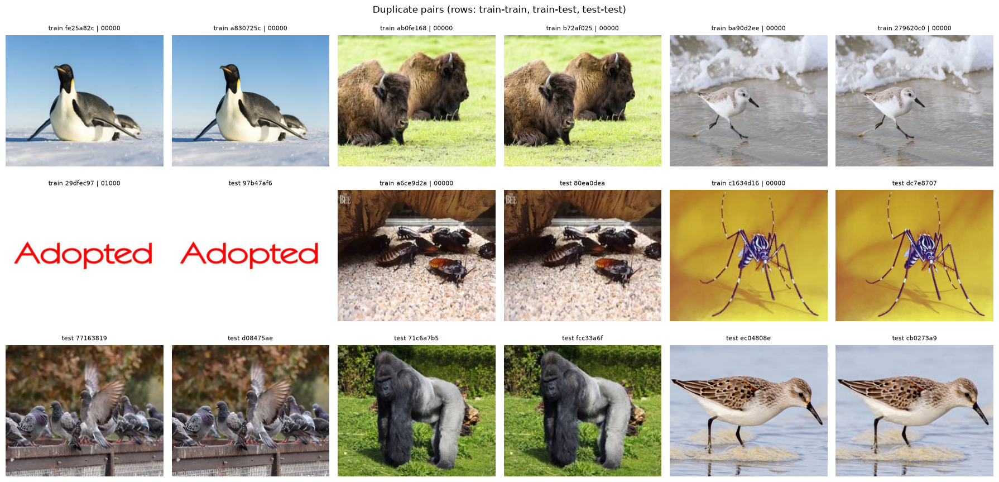

In [23]:
def dup_title(r):
    return f"{r.split} {r.image_id[:8]} | {label_code(r, LABELS)}" if r.split == "train" else f"{r.split} {r.image_id[:8]}"

# One grid row per kind, 3 example pairs side by side
rows = []
for kind in ["train-train", "train-test", "test-test"]:
    examples = pairs[pairs.kind == kind].sample(3, random_state=SEED)
    rows.append(all_imgs.loc[np.ravel(examples[["i", "j"]].values)])
show_grid(rows, title=dup_title, suptitle="Duplicate pairs (rows: train-train, train-test, test-test)", ncols=6)

### Label fixes and train deduplication (train only)
Hand-checked wrong train labels and unusable train images, then drop train–train duplicates (found by the near-duplicate check above).
Allowed for train only, never for test (see CLAUDE.md). EDA above shows the original data.

In [24]:
# (image_id, labels after the fix, reason)
LABEL_FIXES = [
    ("97098f0c828f841774abb63b5692fc0a6d7e9321", ["Cat", "Motya"], "only Motya is in the frame, Moris is not visible"),
    ("29dfec973284b3557eadd7177063fef258a33166", [], "placeholder with the text 'Adopted', no animal"),
]

for image_id, new_labels, reason in LABEL_FIXES:
    match = train.image_id == image_id
    assert match.sum() == 1, f"{image_id} not found in train"
    old_labels = label_names(train[match].iloc[0], LABELS)
    rows = train.dup_group == train.dup_group[match].iloc[0]   # the image and its train duplicates
    train.loc[rows, LABELS] = [int(label in new_labels) for label in LABELS]
    print(f"{image_id[:8]}: {old_labels} -> {', '.join(new_labels) or 'none'} ({reason}), {rows.sum()} train copies")

# (image_id, reason): train images left out of training entirely, together with their train duplicates
DROP_IMAGES = [
    ("e6529dc1df879afab018f368f671fb7695ddcb9f", "labelled Cat, but no cat is visible (small Santa photo on a white page)"),
]

for image_id, reason in DROP_IMAGES:
    match = train.image_id == image_id
    assert match.sum() == 1, f"{image_id} not found in train"
    rows = train.dup_group == train.dup_group[match].iloc[0]
    train = train[~rows]
    print(f"{image_id[:8]}: dropped ({reason}), {rows.sum()} train copies")

# Train-train duplicates: keep the first image of each duplicate group, drop the rest
is_dup = train.dup_group.duplicated()
train = train[~is_dup].reset_index(drop=True)
print(f"Dropped {is_dup.sum()} train duplicates -> {len(train)} train images")

97098f0c: Cat, Moris, Motya -> Cat, Motya (only Motya is in the frame, Moris is not visible), 1 train copies
29dfec97: Dog -> none (placeholder with the text 'Adopted', no animal), 1 train copies
e6529dc1: dropped (labelled Cat, but no cat is visible (small Santa photo on a white page)), 1 train copies
Dropped 162 train duplicates -> 12097 train images


## 5. Validation: multilabel stratified hold-out or K-fold
Each rare class has only 41–56 positives. A plain random K-fold can easily give one fold 4 Biatrix images and another 14,
and a single 80/20 hold-out leaves only ~10 positives per rare class to tune thresholds on.
With 3 folds each val fold has 13–19 positives per rare class.

**Iterative stratification** (Sechidis et al., 2011; `iterstrat.MultilabelStratifiedKFold`) assigns images to folds one label
at a time, starting with the rarest, so **every label** is split as evenly as possible. We add a `none` column (no label at all)
so the background images are balanced across folds too.

- **No leakage between folds:** train–train duplicates were dropped above, and the EDA found no other groups (no bursts of photos from one shoot).
- **Out-of-fold (OOF) predictions:** every train image is predicted once, by the model that did not see it. Thresholds are
  tuned on all ~50 positives of each rare class, and the **CV score** is macro F1 on the OOF predictions.
- **Test:** the average of the fold models' probabilities (ensembling by averaging).

**For now `n_folds=1`:** one model on a single stratified hold-out (`MultilabelStratifiedShuffleSplit`, `val_frac` = 20%
of train as val, about 11 positives per rare class). It is faster to iterate on, but the val score and thresholds are noisier.
The val images are "fold 0", the rest is marked `-1` (train only). Set `n_folds` to 3 or 5 for full CV.

In [25]:
strat_targets = train[LABELS].assign(none=(train[LABELS].sum(axis=1) == 0).astype(int))
if CFG["n_folds"] == 1:
    splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=CFG["val_frac"], random_state=SEED)
else:
    splitter = MultilabelStratifiedKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=SEED)

train["fold"] = -1   # -1 = never in val (only used with n_folds=1)
for fold, (_, val_rows) in enumerate(splitter.split(train, strat_targets)):
    train.loc[val_rows, "fold"] = fold

fold_counts = strat_targets.groupby(train.fold).sum()
fold_counts.insert(0, "images", train.fold.value_counts().sort_index())
display(fold_counts.rename(index={-1: "train only"}))

,images,Cat,Dog,Moris,Motya,Biatrix,none
fold,,,,,,,
train only,9677,4057,4016,44,34,32,1607
0,2420,1015,1004,11,8,8,402


## 6. Dataset, augmentations, model (ImageNet-pretrained EfficientNet-B4)
**EfficientNet** (Tan & Le, 2019) is a CNN family (B0–B7) built from one small baseline network. Each bigger version scales
depth, width and input resolution together with one "compound" coefficient. Its building block is the **MBConv**
(inverted residual: 1×1 expand → 3×3/5×5 depthwise conv → Squeeze-and-Excitation → 1×1 project, with a skip connection).
SE reweights the channels per image, which helps with fine detail like the fur patterns that tell Moris, Motya and Biatrix apart.

We use **B4** (~18M parameters) at 384 px, its evaluation resolution in `timm` (trained at 320). Compared with B2 at 288 px it is
deeper and wider and sees more detail, which matters because the identity classes are fine-grained.

In [26]:
S = CFG["img_size"]

def _load(p):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize((S, S), Image.BILINEAR), dtype=np.uint8)

def load_all(paths, name):
    paths = list(paths)
    f = CACHE_DIR / f"{name}_{len(paths)}_{S}.npy"   # cache key = split name + image count + size
    if os.path.exists(f):
        return np.load(f)
    t0 = time.time()
    arr = np.empty((len(paths), S, S, 3), dtype=np.uint8)
    with Pool(os.cpu_count()) as pool:
        for i, a in enumerate(pool.imap(_load, paths, chunksize=64)):
            arr[i] = a
    np.save(f, arr)
    print(f"{name}: {arr.shape} decoded in {time.time() - t0:.0f}s")
    return arr

X_train_all = load_all(train.path, "train")      # NHWC uint8, same row order as `train` (after dedup)
X_test = load_all(test.path, "test")             # same row order as test.csv / sample_submission
print("train", X_train_all.shape, f"{X_train_all.nbytes / 1e9:.1f} GB | test", X_test.shape, f"{X_test.nbytes / 1e9:.1f} GB")

Y_train_all = train[LABELS].values               # 0/1 labels, same row order as X_train_all

train (12097, 384, 384, 3) 5.4 GB | test (18673, 384, 384, 3) 8.3 GB


In [27]:
# Normalise with the statistics the backbone was pretrained with (timm stores them per model)
PRETRAINED_CFG = timm.get_pretrained_cfg(CFG["model_name"])
print("pretrained input size:", PRETRAINED_CFG.input_size, "| mean:", PRETRAINED_CFG.mean, "| std:", PRETRAINED_CFG.std)

MEAN_T = torch.tensor(PRETRAINED_CFG.mean, device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor(PRETRAINED_CFG.std, device=DEVICE).view(1, 3, 1, 1)

def prep(xb):
    """uint8 NHWC (any device) -> float NCHW in [0,1] on DEVICE"""
    return torch.as_tensor(xb).to(DEVICE, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)

def normalize(x):
    return ((x - MEAN_T) / STD_T).contiguous(memory_format=torch.channels_last)

pretrained input size: (3, 320, 320) | mean: (0.485, 0.456, 0.406) | std: (0.229, 0.224, 0.225)


### Train augmentations (`torchvision.transforms.v2`)
Applied per image in the DataLoader workers, so every image gets its own random crop, flip and colour change.
Each one covers variation seen in the EDA. Val and test images are not augmented.

In [28]:
train_tf = v2.Compose([
    v2.ToImage(),   # HWC uint8 numpy -> CHW uint8 tensor

    # Mild crop (each side keeps >= ~88%): stronger crops can cut a cat or dog out at the image
    # edge while its label stays 1, e.g. one of two cats in a Moris + Motya photo
    v2.RandomResizedCrop(S, scale=(0.85, 1.0), ratio=(0.9, 1.1), antialias=True),

    # Pets look the same mirrored. No vertical flip or rotation: photos are upright
    v2.RandomHorizontalFlip(p=0.5),

    # Exposure and colour differences between photos
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),

    # Old black-and-white photos (EDA: ~1% grayscale images)
    v2.RandomGrayscale(p=0.05),

    # Blurry, upscaled photos (EDA: blurry images)
    v2.RandomApply([v2.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.1),
])
# Output stays uint8: the GPU does the float conversion and ImageNet normalisation, same as for val/test

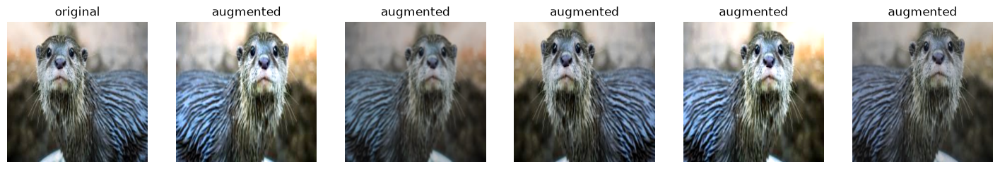

In [29]:
# Sanity check: one train image and a few augmented versions of it
img = X_train_all[0]
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(img)
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(train_tf(img).permute(1, 2, 0).numpy())
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()

In [30]:
class TrainDataset(Dataset):
    """Pre-resized uint8 images + 0/1 labels; applies `transform` to one image at a time."""

    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = torch.tensor(labels, dtype=torch.float32)
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.transform(self.images[i]), self.labels[i]


def make_train_loader(rows):
    """Augmented, shuffled batches of the train rows of one fold."""
    return DataLoader(
        TrainDataset(X_train_all[rows], Y_train_all[rows], train_tf),
        batch_size=CFG["batch_size"],
        shuffle=True,
        drop_last=True,   # drop the last partial batch (keeps BatchNorm stable)
        num_workers=CFG["num_workers"],
        pin_memory=True,
    )

### Model: EfficientNet backbone + 5 independent sigmoid outputs
`num_classes=5` replaces the 1000-class ImageNet head with a new linear layer. Each output is its own yes/no classifier
(sigmoid + binary cross-entropy, no softmax), so a Moris photo can be `Cat = 1` and `Moris = 1` at the same time.

Every fold trains a fresh model, so model and optimizer creation are functions.

In [31]:
def build_model():
    model = timm.create_model(
        CFG["model_name"],
        pretrained=True,
        num_classes=len(LABELS),
        drop_rate=CFG["drop_rate"],
        drop_path_rate=CFG["drop_path_rate"],
    )
    return model.to(DEVICE).to(memory_format=torch.channels_last)

model = build_model()
print(f"{CFG['model_name']}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")
print("stages:", [name for name, _ in model.named_children()])
print("new head:", model.get_classifier())
del model   # each fold builds its own

efficientnet_b4.ra2_in1k: 17.6M parameters
stages: ['conv_stem', 'bn1', 'blocks', 'conv_head', 'bn2', 'global_pool', 'classifier']
new head: Linear(in_features=1792, out_features=5, bias=True)


In [32]:
def build_training(model, steps_per_epoch):
    """Loss, optimizer, LR schedule and AMP scaler for one fold."""
    criterion = nn.BCEWithLogitsLoss()   # plain BCE, every positive and negative counts the same

    # Two parameter groups: the new head starts from random weights and needs a higher LR than the pretrained body
    head_params = list(model.get_classifier().parameters())
    head_ids = {id(p) for p in head_params}
    body_params = [p for p in model.parameters() if id(p) not in head_ids]
    max_lrs = [CFG["lr"] * CFG["backbone_lr_mult"], CFG["lr"]]   # [body, head]
    optimizer = torch.optim.AdamW(
        [{"params": body_params, "name": "body"}, {"params": head_params, "name": "head"}],
        lr=CFG["lr"], weight_decay=CFG["weight_decay"],
    )

    # Warm up for the first 10% of steps (at least 2 steps, debug runs are tiny), then cosine decay to ~0
    total_steps = steps_per_epoch * CFG["epochs"]
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=max_lrs, total_steps=total_steps, pct_start=max(0.1, 2 / total_steps),
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    return criterion, optimizer, scheduler, scaler

### Training data per class (before and after augmentation)
Augmentation does **not** add images to the dataset: each epoch, every train image is loaded once and gets a new random
crop, flip and colour change. So the number of images per class stays the same, and what grows is the number of different
**augmented views** the model sees during training (images × epochs). The class balance is unchanged: Moris, Motya and
Biatrix stay below 0.5% of what the model sees.

train_images  augmented_views  val_images
fold label                                             
0    Cat              4057            81140        1015
     Dog              4016            80320        1004
     Moris              44              880          11
     Motya              34              680           8
     Biatrix            32              640           8
     none             1607            32140         402

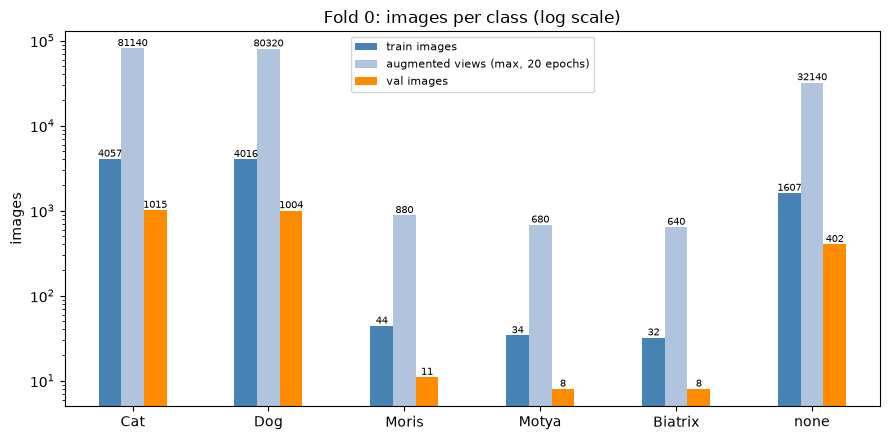

In [33]:
CLASSES = LABELS + ["none"]                                    # "none" = images without any label
Y_classes = np.c_[Y_train_all, Y_train_all.sum(axis=1) == 0]

rows = []
for k in FOLDS:
    train_rows = np.where(train.fold != k)[0]
    val_rows = np.where(train.fold == k)[0]
    for j, cls in enumerate(CLASSES):
        n_train = int(Y_classes[train_rows, j].sum())
        rows.append(dict(
            fold=k,
            label=cls,
            train_images=n_train,
            augmented_views=n_train * CFG["epochs"],   # at most: once per epoch, augmented differently each time
            val_images=int(Y_classes[val_rows, j].sum()),
        ))
train_counts = pd.DataFrame(rows).set_index(["fold", "label"])
display(train_counts)

fig, axes = plt.subplots(1, len(FOLDS), figsize=(9 * len(FOLDS), 4.5), squeeze=False)
for ax, (k, counts) in zip(axes[0], train_counts.groupby(level="fold")):
    counts.droplevel("fold").plot.bar(ax=ax, logy=True, rot=0, color=["steelblue", "lightsteelblue", "darkorange"])
    for bars in ax.containers:
        ax.bar_label(bars, fontsize=7)
    ax.set(title=f"Fold {k}: images per class (log scale)", xlabel="", ylabel="images")
    ax.legend(["train images", f"augmented views (max, {CFG['epochs']} epochs)", "val images"], fontsize=8)
plt.tight_layout()
plt.show()

## 7. Training: one model per fold, with logging
Logged every epoch: train/val loss, val mAP (threshold-free), val macro F1 at threshold 0.5, AP per class and both learning rates.
**Best checkpoint and early stopping** use the val loss. An epoch only counts as an improvement when the val loss drops by more
than `min_delta` below the best so far; then its checkpoint is saved. After `patience` epochs in a row without an improvement,
training stops. The saved best checkpoint then predicts its val fold (OOF) and the test set.

Every `grad_log_every` steps we also record the **gradient norm of each network stage** (stem, `blocks.0`–`blocks.6`, head)
for the gradient-flow plot below.

In [34]:
@torch.no_grad()
def predict_logits(model, X, bs=256):
    """Raw model outputs for uint8 NHWC images (numpy or GPU tensor), in batches."""
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        x = normalize(prep(X[i:i + bs]))
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            out.append(model(x).float().cpu())
    return torch.cat(out)

def predict_proba(model, X):
    return torch.sigmoid(predict_logits(model, X)).numpy()


def stage_of(param_name):
    """Group parameters by network stage: 'blocks.3.1.conv_pw.weight' -> 'blocks.3', 'conv_stem.weight' -> 'conv_stem'."""
    parts = param_name.split(".")
    return ".".join(parts[:2]) if parts[0] == "blocks" else parts[0]

STAGES = list(dict.fromkeys(stage_of(n) for n, _ in build_model().named_parameters()))   # in forward order

def grad_norms_by_stage(model):
    """L2 norm of the gradient of each stage (call after the gradients are unscaled)."""
    sq = {s: torch.zeros((), device=DEVICE) for s in STAGES}
    for name, p in model.named_parameters():
        if p.grad is not None:
            sq[stage_of(name)] += p.grad.float().pow(2).sum()
    norms = torch.stack(list(sq.values())).sqrt().tolist()   # one GPU -> CPU copy for all stages
    return dict(zip(STAGES, norms))


def evaluate(model, X, y, criterion):
    """Val loss, mAP, macro F1 at 0.5 and AP per class."""
    logits = predict_logits(model, X)
    loss = criterion(logits.to(DEVICE), torch.tensor(y, dtype=torch.float32, device=DEVICE)).item()
    p = torch.sigmoid(logits).numpy()
    ap = {lab: average_precision_score(y[:, j], p[:, j]) for j, lab in enumerate(LABELS) if y[:, j].sum() > 0}
    return dict(
        val_loss=loss,
        val_mAP=np.mean(list(ap.values())),
        val_macroF1_t05=f1_score(y, (p > 0.5).astype(int), average="macro", zero_division=0),
        **{f"AP_{lab}": v for lab, v in ap.items()},
    )

In [35]:
def train_one_fold(fold):
    """Train a fresh model on all folds but `fold`. Returns logs, OOF and test probabilities of the best epoch."""
    train_rows = np.where(train.fold != fold)[0]
    val_rows = np.where(train.fold == fold)[0]
    if CFG["debug"]:   # tiny subset for a quick pipeline check
        train_rows, val_rows = train_rows[:640], val_rows[:256]

    train_dl = make_train_loader(train_rows)
    steps = len(train_dl)
    Xva = torch.from_numpy(X_train_all[val_rows]).to(DEVICE)   # val images live on the GPU as uint8, no augmentation
    yv = Y_train_all[val_rows]
    print(f"--- fold {fold}: train {len(train_rows)} images ({steps} steps/epoch) | val {len(val_rows)} images")

    model = build_model()
    criterion, optimizer, scheduler, scaler = build_training(model, steps)
    ckpt_path = OUT_DIR / f"{RUN_NAME}_fold{fold}.pth"
    history, grad_log = [], []
    best_loss, epochs_without_improvement, step = np.inf, 0, 0

    for epoch in range(1, CFG["epochs"] + 1):
        model.train()
        t0 = time.time()
        run_loss = torch.zeros((), device=DEVICE)   # accumulate on the GPU: no per-step .item() sync

        for x, y in train_dl:
            x = normalize(x.to(DEVICE, non_blocking=True).float().div_(255))   # augmented uint8 NCHW -> normalised float
            y = y.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward()

            if step % CFG["grad_log_every"] == 0:
                scaler.unscale_(optimizer)              # real gradient sizes, not the AMP-scaled ones
                grad_log.append(dict(fold=fold, step=step, epoch=epoch, **grad_norms_by_stage(model)))

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            run_loss += loss.detach()
            step += 1

        train_time = time.time() - t0
        metrics = evaluate(model, Xva, yv, criterion)
        lrs = {f"lr_{g['name']}": g["lr"] for g in optimizer.param_groups}
        # Early stopping: only a val loss drop larger than min_delta counts as an improvement
        improved = metrics["val_loss"] < best_loss - CFG["min_delta"]
        if improved:
            best_loss, epochs_without_improvement = metrics["val_loss"], 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            epochs_without_improvement += 1

        history.append(dict(fold=fold, epoch=epoch, train_loss=run_loss.item() / steps, **metrics, **lrs,
                            img_per_s=steps * CFG["batch_size"] / train_time, is_best=improved))
        h = history[-1]
        print(f"fold {fold} epoch {epoch:2d} | train loss {h['train_loss']:.4f} | val loss {h['val_loss']:.4f} | "
              f"mAP {h['val_mAP']:.4f} | macro F1@0.5 {h['val_macroF1_t05']:.4f} | "
              f"lr head {h['lr_head']:.1e} | {train_time:.0f}s ({h['img_per_s']:.0f} img/s)"
              + ("  * best" if improved else f"  (no improvement {epochs_without_improvement}/{CFG['patience']})"))

        if epochs_without_improvement >= CFG["patience"]:
            print(f"early stop after epoch {epoch}: val loss did not drop by more than {CFG['min_delta']} "
                  f"for {CFG['patience']} epochs (best {best_loss:.4f})")
            break

    # Predict with the best epoch, not the last one
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    result = dict(
        history=pd.DataFrame(history),
        grads=pd.DataFrame(grad_log),
        val_rows=val_rows,
        oof=predict_proba(model, Xva),
        test=predict_proba(model, X_test),   # X_test: numpy uint8, streamed to the GPU in chunks
    )
    del model, Xva
    torch.cuda.empty_cache()
    return result

In [36]:
oof = np.full((len(train), len(LABELS)), np.nan)   # out-of-fold probabilities, filled fold by fold (NaN = not predicted)
test_fold_probs, histories, grad_logs = [], [], []

for fold in FOLDS:
    result = train_one_fold(fold)
    oof[result["val_rows"]] = result["oof"]
    test_fold_probs.append(result["test"])
    histories.append(result["history"])
    grad_logs.append(result["grads"])

hist = pd.concat(histories, ignore_index=True)
grads = pd.concat(grad_logs, ignore_index=True)
hist.to_csv(OUT_DIR / f"{RUN_NAME}_history.csv", index=False)
grads.to_csv(OUT_DIR / f"{RUN_NAME}_grad_norms.csv", index=False)
np.save(OUT_DIR / f"oof_probs_{RUN_NAME}.npy", oof)   # same row order as `train`: reuse for ensembling / stacking

# Best epoch of each fold (the checkpoint used for OOF and test) and how long each fold trained
best = hist[hist.is_best].groupby("fold").tail(1)[["fold", "epoch", "val_loss", "val_mAP", "val_macroF1_t05"]]
best = best.assign(epochs_trained=hist.groupby("fold").epoch.max().values)
display(best.set_index("fold").round(4))
print(f"val mAP of the best epochs: {best.val_mAP.mean():.4f} ± {best.val_mAP.std(ddof=0):.4f}")

--- fold 0: train 9677 images (151 steps/epoch) | val 2420 images
fold 0 epoch  1 | train loss 0.5693 | val loss 0.1758 | mAP 0.3882 | macro F1@0.5 0.3564 | lr head 5.2e-04 | 50s (192 img/s)  * best
fold 0 epoch  2 | train loss 0.0951 | val loss 0.0417 | mAP 0.4100 | macro F1@0.5 0.3921 | lr head 1.0e-03 | 23s (424 img/s)  * best
fold 0 epoch  3 | train loss 0.0375 | val loss 0.0257 | mAP 0.5871 | macro F1@0.5 0.3950 | lr head 9.9e-04 | 23s (426 img/s)  * best
fold 0 epoch  4 | train loss 0.0232 | val loss 0.0188 | mAP 0.7399 | macro F1@0.5 0.5206 | lr head 9.7e-04 | 22s (436 img/s)  * best
fold 0 epoch  5 | train loss 0.0140 | val loss 0.0163 | mAP 0.8105 | macro F1@0.5 0.5659 | lr head 9.3e-04 | 23s (417 img/s)  * best
fold 0 epoch  6 | train loss 0.0102 | val loss 0.0151 | mAP 0.8801 | macro F1@0.5 0.6443 | lr head 8.8e-04 | 23s (422 img/s)  * best
fold 0 epoch  7 | train loss 0.0075 | val loss 0.0133 | mAP 0.9198 | macro F1@0.5 0.6741 | lr head 8.2e-04 | 24s (404 img/s)  * best
fol

,epoch,val_loss,val_mAP,val_macroF1_t05,epochs_trained
fold,,,,,
0,11,0.0101,0.9604,0.8174,14


val mAP of the best epochs: 0.9604 ± 0.0000


### Training curves
One line per fold, the star marks the saved (best) epoch. Train loss is the mean over the epoch with augmentation and dropout on, so it can sit above the val loss
early on. A val loss that rises while the train loss keeps falling means overfitting. The spread between folds shows
how noisy the val metrics are (each val fold has only 13–19 positives per rare class).

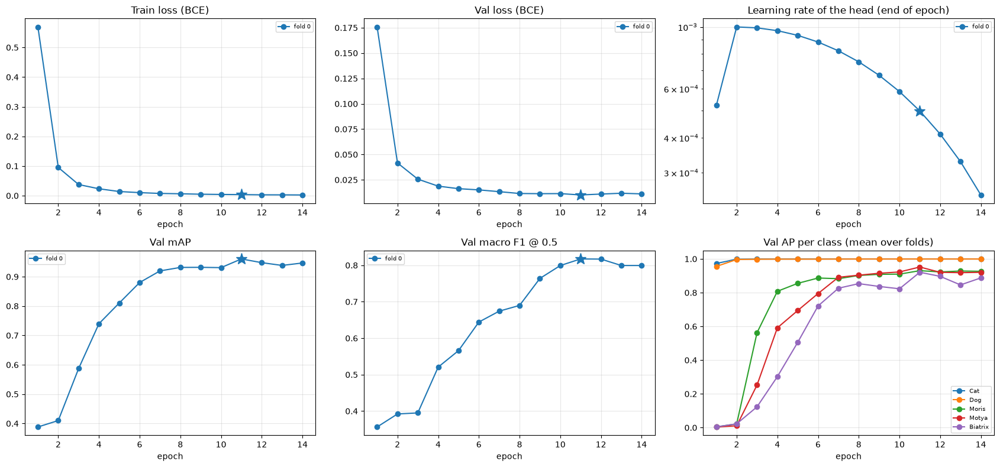

In [37]:
panels = [
    ("train_loss", "Train loss (BCE)", False),
    ("val_loss", "Val loss (BCE)", False),
    ("lr_head", "Learning rate of the head (end of epoch)", True),
    ("val_mAP", "Val mAP", False),
    ("val_macroF1_t05", "Val macro F1 @ 0.5", False),
]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (col, title, logy) in zip(axes.ravel(), panels):
    for fold, h in hist.groupby("fold"):
        line, = ax.plot(h.epoch, h[col], marker="o", label=f"fold {fold}")
        b = h[h.is_best].iloc[-1]   # the saved checkpoint
        ax.plot(b.epoch, b[col], marker="*", ms=14, color=line.get_color(), ls="none")
    ax.set(title=title, xlabel="epoch", yscale="log" if logy else "linear")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

# Last panel: AP per class, mean over folds. Cat and Dog saturate early, the identity classes are where the model still learns
ap_cols = [c for c in hist.columns if c.startswith("AP_")]
mean_ap = hist.groupby("epoch")[ap_cols].mean()
for col in ap_cols:
    axes[1, 2].plot(mean_ap.index, mean_ap[col], marker="o", label=col.removeprefix("AP_"))
axes[1, 2].set(title="Val AP per class (mean over folds)", xlabel="epoch")
axes[1, 2].grid(alpha=0.3)
axes[1, 2].legend(fontsize=7)

plt.tight_layout()
plt.show()

### Gradient flow (fold 0)
Gradient norm of each stage, from the input side (`conv_stem`) to the output side (`classifier`).
- **Healthy:** every stage gets a non-zero gradient that shrinks smoothly as the LR schedule decays.
- **Vanishing gradients:** early stages near zero while the head is large, so the pretrained body hardly adapts.
- **Exploding gradients:** spikes by orders of magnitude, often together with loss spikes.

The very first step can be missing for some stages: AMP starts with a large loss scale, the gradients overflow, and that step is skipped.

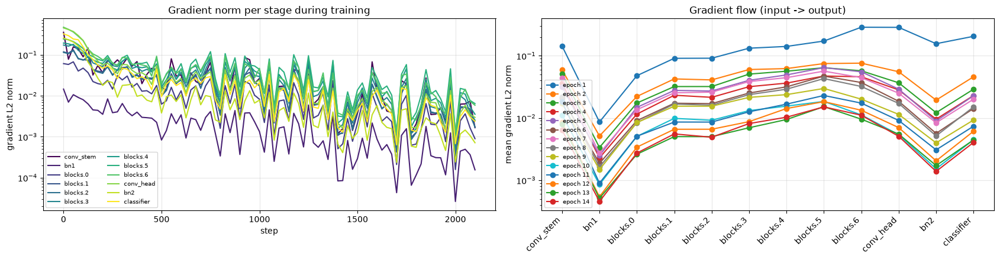

In [38]:
g0 = grads[grads.fold == FOLDS[0]]
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))

# Left: each stage over training steps
colors = plt.cm.viridis(np.linspace(0, 1, len(STAGES)))
for stage, c in zip(STAGES, colors):
    axes[0].plot(g0.step, g0[stage], color=c, label=stage)
axes[0].set(yscale="log", xlabel="step", ylabel="gradient L2 norm", title="Gradient norm per stage during training")
axes[0].legend(fontsize=7, ncol=2)

# Right: mean per stage for each epoch (input -> output)
per_epoch = g0.groupby("epoch")[STAGES].mean()
for epoch, row in per_epoch.iterrows():
    axes[1].plot(range(len(STAGES)), row.values, marker="o", label=f"epoch {epoch}")
axes[1].set_xticks(range(len(STAGES)), STAGES, rotation=45, ha="right")
axes[1].set(yscale="log", ylabel="mean gradient L2 norm", title="Gradient flow (input -> output)")
axes[1].legend(fontsize=7)

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. CV score and per-class thresholds (out-of-fold)
One threshold **per class**, the one that maximises F1 on the OOF predictions: the val images of every trained fold
(all train images with K-fold, the 20% hold-out with `n_folds=1`). The CV macro F1 is slightly optimistic, because the thresholds are tuned on the
same OOF predictions they are scored on. The per-fold scores show the spread.

The label hierarchy is then enforced: `Moris`/`Motya` → `Cat`, `Biatrix` → `Dog`.

In [39]:
def enforce_hierarchy(pred):
    """0/1 predictions (N, 5): an identity label switches on its species label."""
    pred = pred.copy()
    col = {lab: j for j, lab in enumerate(LABELS)}
    pred[:, col["Cat"]] |= pred[:, col["Moris"]] | pred[:, col["Motya"]]
    pred[:, col["Dog"]] |= pred[:, col["Biatrix"]]
    return pred

def macro_f1(y, pred):
    return f1_score(y, pred, average="macro", zero_division=0)

has_oof = ~np.isnan(oof).any(axis=1)   # val images: all train images with K-fold, the hold-out with n_folds=1
y_oof, p_oof, oof_fold = Y_train_all[has_oof], oof[has_oof], train.fold.values[has_oof]

grid = np.linspace(0.01, 0.99, 99)
f1_curves = {lab: [f1_score(y_oof[:, j], (p_oof[:, j] > t).astype(int), zero_division=0) for t in grid]
             for j, lab in enumerate(LABELS)}
thresholds = np.array([grid[int(np.argmax(f1_curves[lab]))] for lab in LABELS])
oof_pred = enforce_hierarchy((p_oof > thresholds).astype(int))

res = pd.DataFrame({
    "positives": y_oof.sum(axis=0),
    "AP": [average_precision_score(y_oof[:, j], p_oof[:, j]) for j in range(len(LABELS))],
    "F1_at_0_5": [f1_score(y_oof[:, j], (p_oof[:, j] > 0.5).astype(int), zero_division=0) for j in range(len(LABELS))],
    "threshold": thresholds,
    "F1": [f1_score(y_oof[:, j], oof_pred[:, j], zero_division=0) for j in range(len(LABELS))],
}, index=LABELS).round(3)
display(res)

per_fold_f1 = [macro_f1(y_oof[oof_fold == k], oof_pred[oof_fold == k]) for k in FOLDS]
print(f"CV macro F1 (tuned thresholds + hierarchy): {macro_f1(y_oof, oof_pred):.4f} | "
      f"per fold {np.mean(per_fold_f1):.4f} ± {np.std(per_fold_f1):.4f}")
print("OOF macro AP:", round(res.AP.mean(), 4))

,positives,AP,F1_at_0_5,threshold,F1
Cat,1015,1.000,0.994,0.46,0.995
Dog,1004,0.999,0.994,0.28,0.994
Moris,11,0.930,0.842,0.06,0.870
Motya,8,0.952,0.857,0.09,0.933
Biatrix,8,0.921,0.400,0.04,0.800


CV macro F1 (tuned thresholds + hierarchy): 0.9183 | per fold 0.9183 ± 0.0000
OOF macro AP: 0.9604


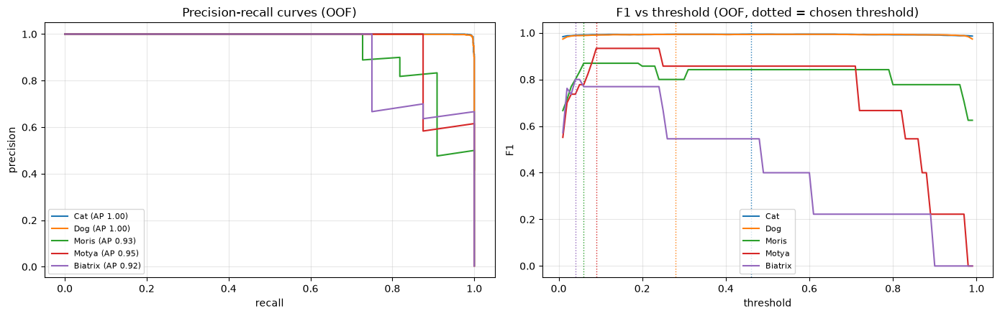

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for j, lab in enumerate(LABELS):
    prec, rec, _ = precision_recall_curve(y_oof[:, j], p_oof[:, j])
    axes[0].plot(rec, prec, label=f"{lab} (AP {res.AP[lab]:.2f})")
    line, = axes[1].plot(grid, f1_curves[lab], label=lab)
    axes[1].axvline(thresholds[j], color=line.get_color(), ls=":", lw=1)
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall curves (OOF)")
axes[1].set(xlabel="threshold", ylabel="F1", title="F1 vs threshold (OOF, dotted = chosen threshold)")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Results per fold and class
Each fold's val images, scored with the shared thresholds above. TP/FP/FN are counts of images: a **false negative (FN)**
is a missed positive, a **false positive (FP)** a wrong "yes".

In [41]:
from sklearn.metrics import precision_score, recall_score

rows = []
for k in FOLDS:
    in_k = oof_fold == k
    for j, lab in enumerate(LABELS):
        y, pred, p = y_oof[in_k, j], oof_pred[in_k, j], p_oof[in_k, j]
        rows.append(dict(
            fold=k,
            label=lab,
            val_positives=int(y.sum()),
            TP=int(((y == 1) & (pred == 1)).sum()),
            FP=int(((y == 0) & (pred == 1)).sum()),
            FN=int(((y == 1) & (pred == 0)).sum()),
            precision=precision_score(y, pred, zero_division=0),
            recall=recall_score(y, pred, zero_division=0),
            F1=f1_score(y, pred, zero_division=0),
            AP=average_precision_score(y, p) if y.sum() > 0 else np.nan,
        ))
fold_results = pd.DataFrame(rows).set_index(["fold", "label"]).round(3)
display(fold_results)

# Compact view: F1 per class (rows) and fold (columns)
f1_table = fold_results.F1.unstack("fold")
f1_table["mean"], f1_table["std"] = f1_table.mean(axis=1), f1_table.std(axis=1, ddof=0)
display(f1_table.round(3))

val_positives    TP  FP  FN  precision  recall     F1     AP
fold label                                                                
0    Cat               1015  1008   4   7      0.996   0.993  0.995  1.000
     Dog               1004  1000   8   4      0.992   0.996  0.994  0.999
     Moris               11    10   2   1      0.833   0.909  0.870  0.930
     Motya                8     7   0   1      1.000   0.875  0.933  0.952
     Biatrix              8     6   1   2      0.857   0.750  0.800  0.921

fold,0,mean,std
label,,,
Biatrix,0.800,0.800,0.0
Cat,0.995,0.995,0.0
Dog,0.994,0.994,0.0
Moris,0.870,0.870,0.0
Motya,0.933,0.933,0.0


### Misclassified images per class and fold
For each class: the most confident mistakes of every fold. Rows go fold 0 FN, fold 0 FP, fold 1 FN, … (a fold with no errors of a type gets no row).
- **FN** (missed positives) are sorted by the lowest predicted probability first.
- **FP** (wrong "yes") are sorted by the highest predicted probability first.

The title shows the fold, error type, predicted probability for the class and the image's true labels.
Repeated patterns across folds (e.g. the same lookalike cat as a Moris FP) point at systematic errors, single odd images often at label noise.

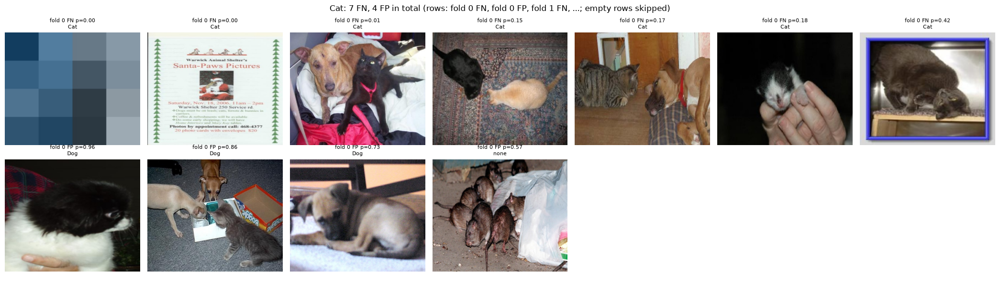

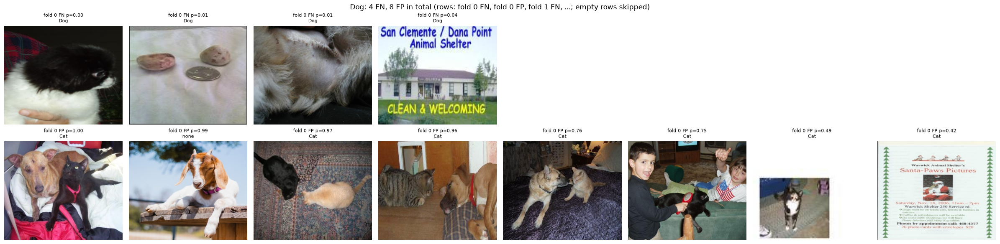

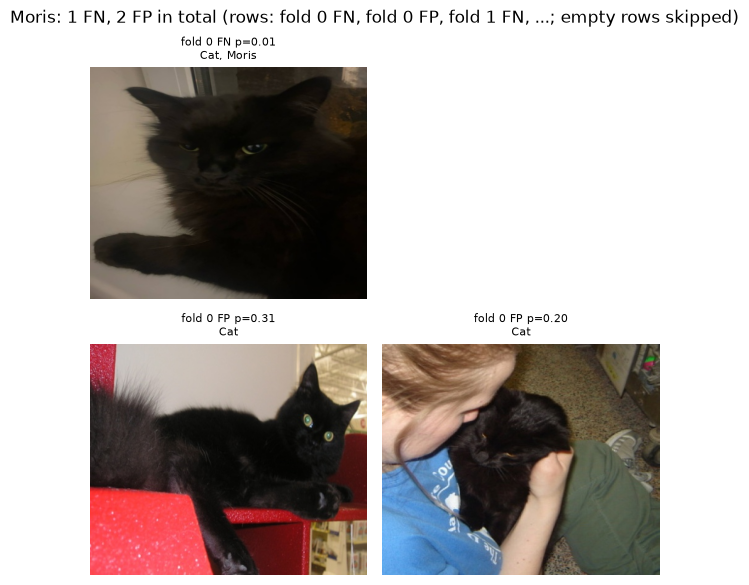

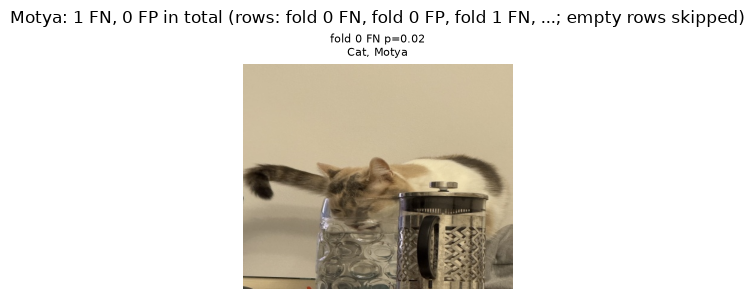

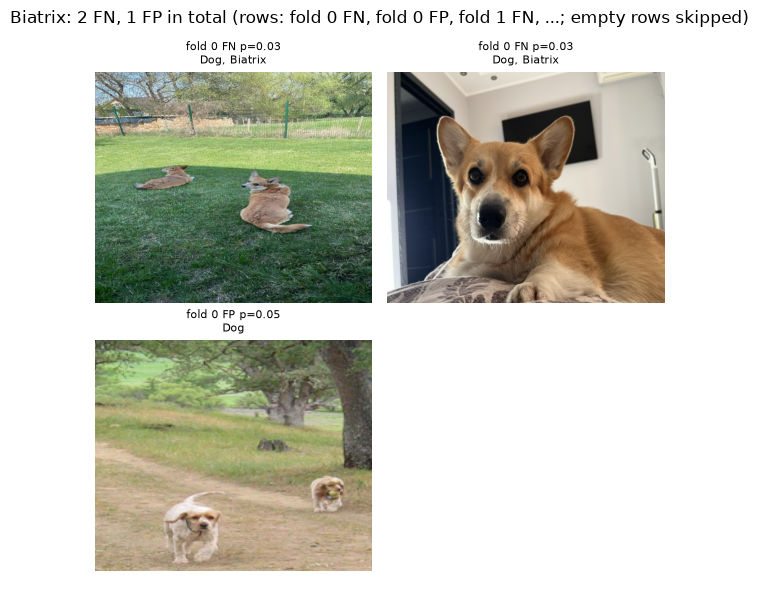

In [42]:
N_SHOW = 8   # images per row: the most confident mistakes of one fold and error type
oof_images = train[has_oof].reset_index(drop=True)   # same row order as y_oof / p_oof

for j, lab in enumerate(LABELS):
    grid_rows = []
    for k in FOLDS:
        for kind, is_error, most_confident_first in [
            ("FN", (y_oof[:, j] == 1) & (oof_pred[:, j] == 0), True),    # lowest probability first
            ("FP", (y_oof[:, j] == 0) & (oof_pred[:, j] == 1), False),   # highest probability first
        ]:
            m = (oof_fold == k) & is_error
            errors = oof_images[m].assign(fold=k, kind=kind, p=p_oof[m, j])
            grid_rows.append(errors.sort_values("p", ascending=most_confident_first).head(N_SHOW))

    n_errors = fold_results.xs(lab, level="label")[["FN", "FP"]].sum()
    if n_errors.sum() == 0:
        print(f"{lab}: no misclassified images")
        continue
    show_grid(
        [r for r in grid_rows if len(r)],   # a fold without FN or FP gets no row
        title=lambda r: f"fold {r.fold} {r.kind} p={r.p:.2f}\n{label_names(r, LABELS)}",
        suptitle=f"{lab}: {n_errors.FN} FN, {n_errors.FP} FP in total (rows: fold 0 FN, fold 0 FP, fold 1 FN, ...; empty rows skipped)",
        ncols=N_SHOW,
    )

## 9. Predict test & write the submission
Test probabilities are the **mean of the fold models** (ensembling by averaging; a single model with `n_folds=1`), then the OOF thresholds and the hierarchy are applied.

In [43]:
test_p = np.mean(test_fold_probs, axis=0)
test_pred = enforce_hierarchy((test_p > thresholds).astype(int))

submission = pd.DataFrame(test_pred, columns=LABELS)
submission.insert(0, "image_id", test.image_id.values)

assert list(submission.columns) == list(sample_sub.columns)
assert (submission.image_id.values == sample_sub.image_id.values).all()
out_name = "submission_DEBUG_do_not_submit.csv" if CFG["debug"] else f"submission_{RUN_NAME}_{'holdout' if CFG['n_folds'] == 1 else str(CFG['n_folds']) + 'fold'}.csv"
submission.to_csv(OUT_DIR / out_name, index=False)
np.save(OUT_DIR / f"test_probs_{RUN_NAME}.npy", test_p)    # fold-averaged probabilities: reuse for ensembling
print("saved", out_name)
display(submission.head())
print("Predicted positive rate (test) vs train prevalence:")
display(pd.DataFrame({"test_pred_%": (submission[LABELS].mean() * 100).round(2), "train_%": (train[LABELS].mean() * 100).round(2)}))

saved submission_efficientnet_b4_holdout.csv


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24,0,0,0,0,0
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c,0,1,0,0,0
2,ac89f642faef21c92d622d882943e9065600354a,0,0,0,0,0
3,7245e7046ae54da95dbddc24ae814b3c61cc6237,1,0,0,0,0
4,d2b76179615de57b54cb00d094fba50810d96127,1,0,0,0,0


Predicted positive rate (test) vs train prevalence:


,test_pred_%,train_%
Cat,41.57,41.93
Dog,41.17,41.50
Moris,0.98,0.45
Motya,0.69,0.35
Biatrix,1.02,0.33
